In [1]:
from UMA_23L.id4 import Node, buildTree, predict
import pandas as pd
from sklearn.model_selection import train_test_split

data = pd.read_csv("./mushrooms.csv")
train_data, test_data = train_test_split(data, test_size=0.5, random_state=0)
X_train = train_data.drop(columns=["class"], axis=1)
Y_train = train_data["class"]
X_test = test_data.drop(columns=["class"], axis=1)
Y_test = test_data["class"]

Node.all_classes = list(Y_train.unique())
Node.all_attributes = list(X_train.keys())
for k in X_train.keys():
    Node.possible_values_attribute[k] = list(X_train[k].unique())


# Rozkład klas

<Axes: xlabel='class', ylabel='Count'>

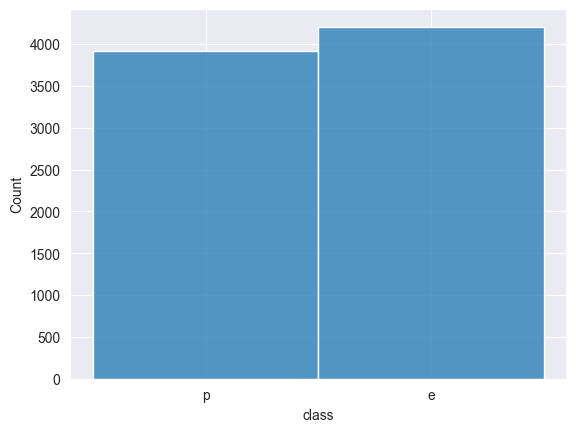

In [2]:
import seaborn
seaborn.histplot(data["class"])

## Uczenie całym zbiorem

In [3]:
tree_batch = Node(Node.all_attributes)

# train tree by batch
tree_batch = buildTree(train_data, tree_batch)
y_pred = predict(test_data, tree_batch)

## Dokładność 100%

W tym konkretnym zbiorze danych jest to osiągalne. Dodatkowy sanity-check: drzewo decyzyjne z funkcji bibliotecznej również osiągnęło ten wynik.

In [4]:
from sklearn.metrics import accuracy_score
accuracy_score(Y_test, y_pred)

1.0

## Uczenie pojedynczymi próbkami

0.9810438207779419


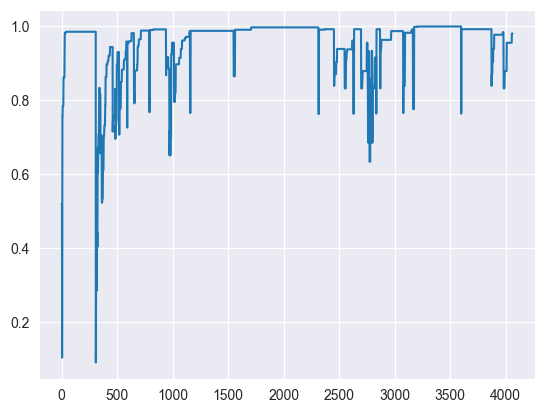

In [5]:
tree_samples = Node(Node.all_attributes)

scores = []
# train tree by single instances
for i, row in train_data.iterrows():
    r_df = pd.DataFrame(row.to_frame().T)
    tree_samples = buildTree(r_df, tree_samples)
    y_pred = predict(test_data, tree_samples)
    scores.append(accuracy_score(Y_test, y_pred))

seaborn.lineplot(scores)
print(scores[-1])

## Drzewo decyzyjne z scikit-learn

In [12]:
from sklearn.tree import DecisionTreeClassifier

dtc = DecisionTreeClassifier(random_state=0)
X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)
Y_train_encoded = pd.get_dummies(Y_train)
Y_test_encoded = pd.get_dummies(Y_test)
dtc.fit(X_train_encoded, Y_train_encoded)

DecisionTreeClassifier(random_state=0)

In [17]:
y_pred = dtc.predict(X_test_encoded)

accuracy_score(Y_test_encoded, y_pred)

1.0